In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("SampleSuperstore.csv")

In [3]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [4]:
df.shape

(9994, 13)

In [5]:
df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB


In [7]:
df.isnull().sum()

Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(17)

In [4]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858001,3.789574,0.156203,28.656896
std,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [5]:
df['Category'].unique()

array(['Furniture', 'Office Supplies', 'Technology'], dtype=object)

In [6]:
df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

In [7]:
df.groupby('Category')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)

,Sales,Profit
Category,,
Technology,836154.0330,145454.9481
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008


In [8]:
df.groupby('Sub-Category')[['Sales', 'Profit']].sum().sort_values(by='Profit', ascending=True)

,Sales,Profit
Sub-Category,,
Tables,206965.5320,-17725.4811
Bookcases,114879.9963,-3472.5560
Supplies,46673.5380,-1189.0995
Fasteners,3024.2800,949.5182
Machines,189238.6310,3384.7569
Labels,12486.3120,5546.2540
Art,27118.7920,6527.7870
Envelopes,16476.4020,6964.1767
Furnishings,91705.1640,13059.1436


In [9]:
df.groupby('Segment')[['Sales', 'Profit']].sum().sort_values(by='Profit', ascending=False)

,Sales,Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


In [10]:
df.groupby('Region')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)

,Sales,Profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
Central,501239.8908,39706.3625
South,391721.9050,46749.4303


In [11]:
df.groupby('Discount')[['Sales', 'Profit']].mean().sort_index()

,Sales,Profit
Discount,,
0.00,226.742074,66.900292
0.10,578.397351,96.055074
0.15,529.971567,27.288298
0.20,209.076940,24.702572
0.30,454.742974,-45.679636
0.32,536.794770,-88.560656
0.40,565.134874,-111.927429
0.45,498.634000,-226.646464
0.50,892.705152,-310.703456


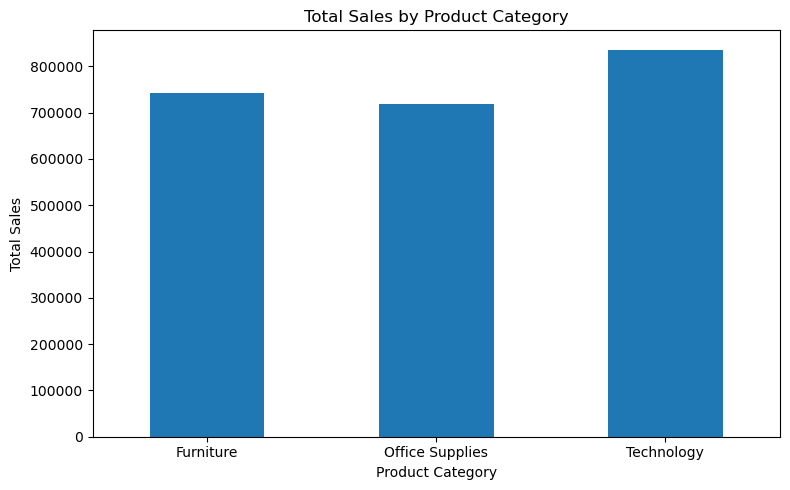

In [12]:
import matplotlib.pyplot as plt

category_sales = df.groupby('Category')['Sales'].sum()

plt.figure(figsize=(8, 5))
category_sales.plot(kind='bar')

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

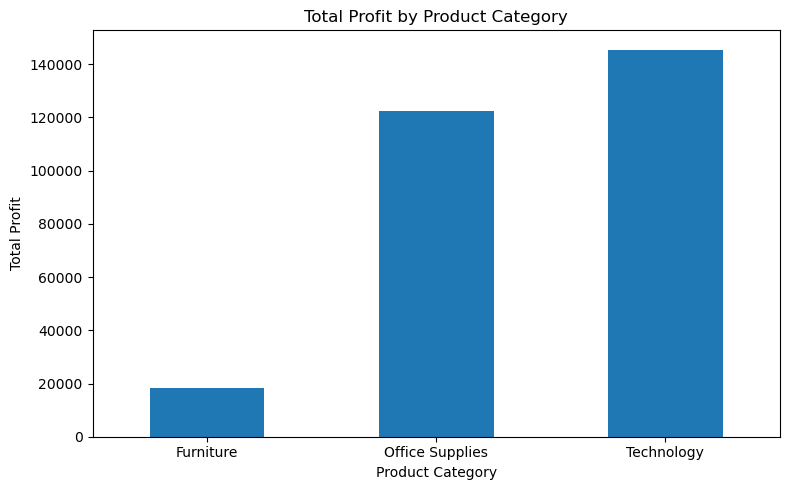

In [13]:
category_profit = df.groupby('Category')['Profit'].sum()

plt.figure(figsize=(8, 5))
category_profit.plot(kind='bar')

plt.title('Total Profit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

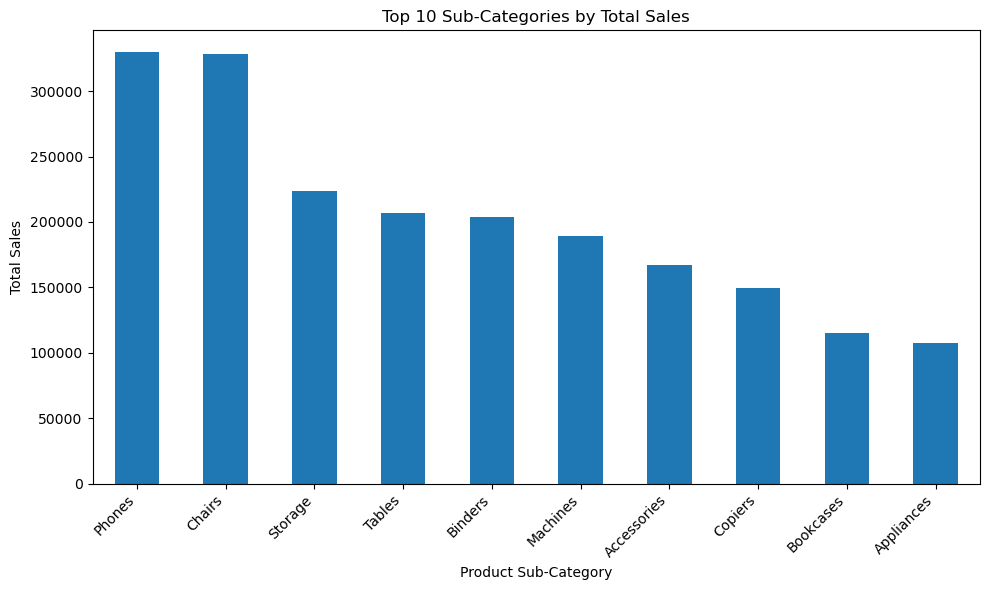

In [14]:
subcategory_sales = df.groupby('Sub-Category')['Sales'].sum()
top_10_sales = subcategory_sales.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
top_10_sales.plot(kind='bar')

plt.title('Top 10 Sub-Categories by Total Sales')
plt.xlabel('Product Sub-Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

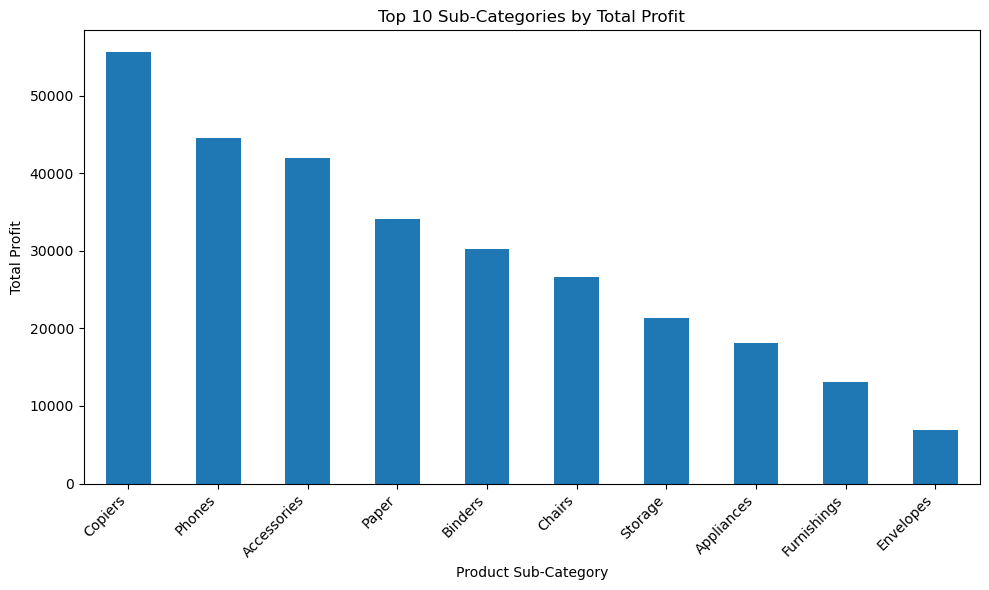

In [15]:
subcategory_profit = df.groupby('Sub-Category')['Profit'].sum()

top_10_profit = subcategory_profit.sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))
top_10_profit.plot(kind='bar')

plt.title('Top 10 Sub-Categories by Total Profit')
plt.xlabel('Product Sub-Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


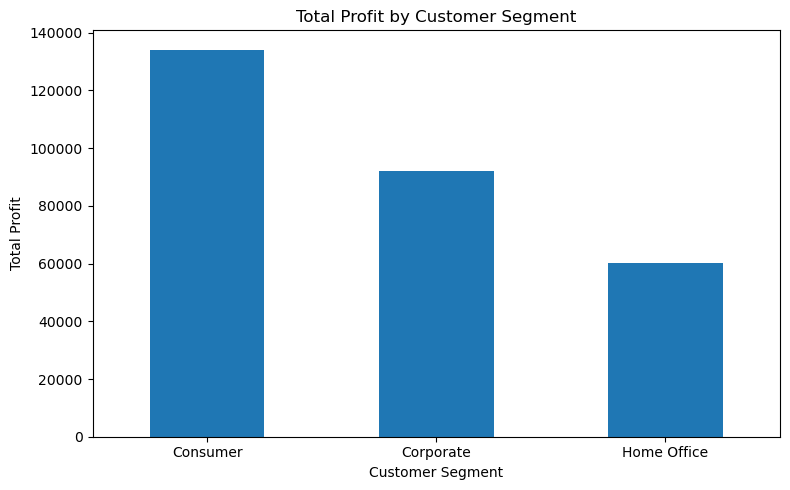

In [16]:
segment_profit = df.groupby('Segment')['Profit'].sum()

plt.figure(figsize=(8, 5))
segment_profit.plot(kind='bar')

plt.title('Total Profit by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

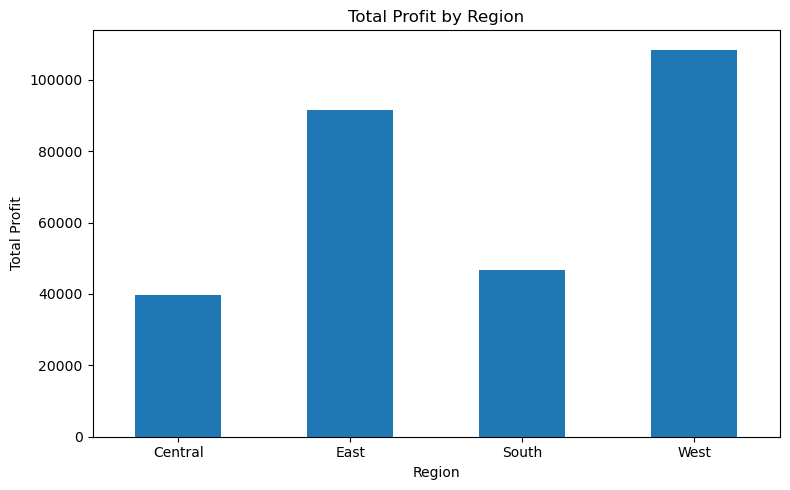

In [17]:
region_profit = df.groupby('Region')['Profit'].sum()

plt.figure(figsize=(8, 5))
region_profit.plot(kind='bar')

plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


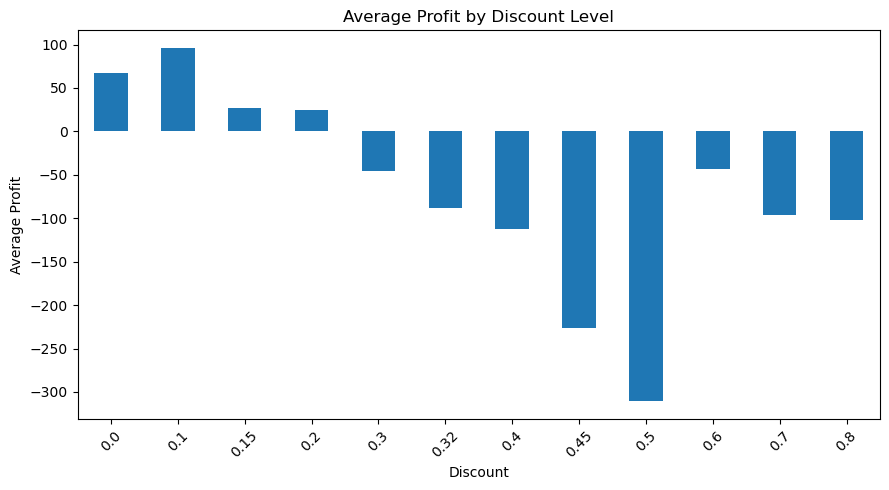

In [19]:
discount_profit = df.groupby('Discount')['Profit'].mean()

plt.figure(figsize=(9, 5))
discount_profit.plot(kind='bar')

plt.title('Average Profit by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Average Profit')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

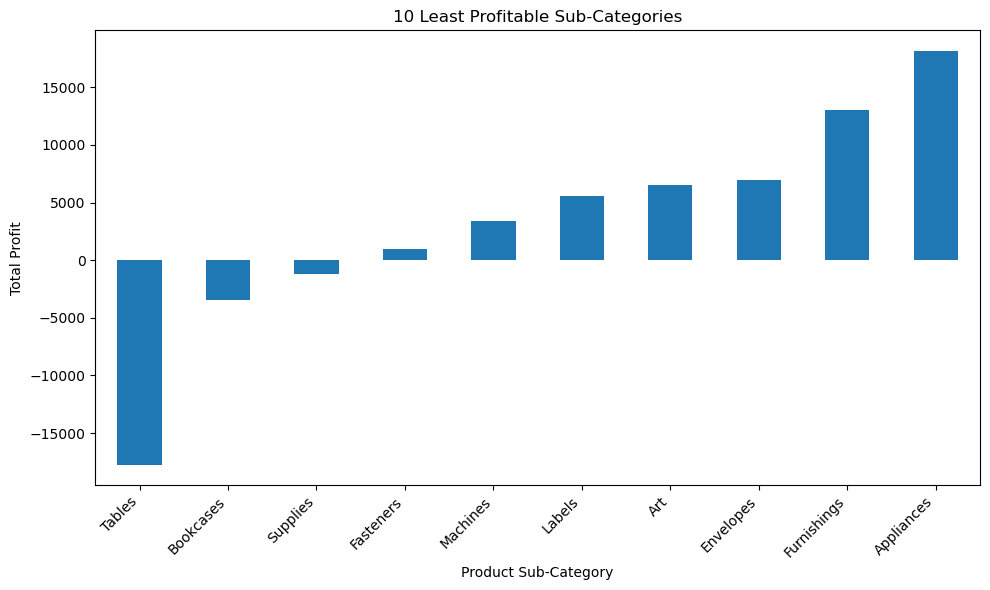

In [20]:
bottom_10_profit = df.groupby('Sub-Category')['Profit'].sum()

bottom_10_profit = bottom_10_profit.sort_values().head(10)

plt.figure(figsize=(10, 6))
bottom_10_profit.plot(kind='bar')

plt.title('10 Least Profitable Sub-Categories')
plt.xlabel('Product Sub-Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

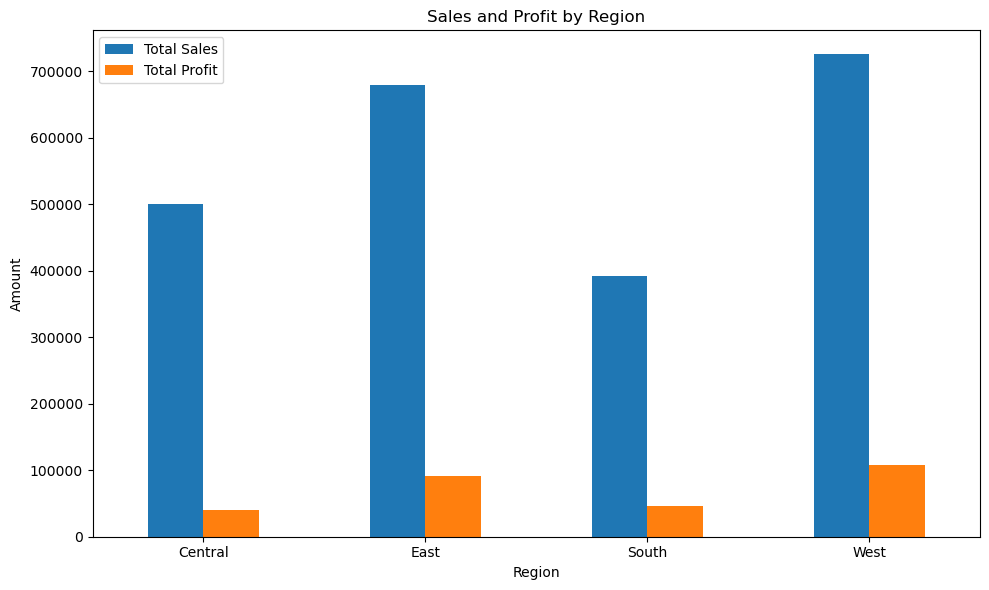

In [21]:
region_performance = df.groupby('Region')[['Sales', 'Profit']].sum()

region_performance.plot(kind='bar', figsize=(10, 6))

plt.title('Sales and Profit by Region')
plt.xlabel('Region')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend(['Total Sales', 'Total Profit'])
plt.tight_layout()
plt.show()

In [22]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
average_sales = df['Sales'].mean()
average_profit = df['Profit'].mean()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Average Sales per Record:", round(average_sales, 2))
print("Average Profit per Record:", round(average_profit, 2))

Total Sales: 2297200.86
Total Profit: 286397.02
Average Sales per Record: 229.86
Average Profit per Record: 28.66


In [23]:
region_profit = df.groupby('Region')['Profit'].sum()

print("Profit by Region:")
print(region_profit.sort_values(ascending=False))

print("\nMost Profitable Region:")
print(region_profit.idxmax())

print("\nLeast Profitable Region:")
print(region_profit.idxmin())

Profit by Region:
Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64

Most Profitable Region:
West

Least Profitable Region:
Central


In [24]:
subcategory_profit = df.groupby('Sub-Category')['Profit'].sum()

print("Profit by Sub-Category:")
print(subcategory_profit.sort_values(ascending=False))

print("\nMost Profitable Sub-Category:")
print(subcategory_profit.idxmax())

print("\nLeast Profitable Sub-Category:")
print(subcategory_profit.idxmin())

Profit by Sub-Category:
Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26590.1663
Storage        21278.8264
Appliances     18138.0054
Furnishings    13059.1436
Envelopes       6964.1767
Art             6527.7870
Labels          5546.2540
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64

Most Profitable Sub-Category:
Copiers

Least Profitable Sub-Category:
Tables


In [25]:
profit_margin = (df['Profit'].sum() / df['Sales'].sum()) * 100

print("Overall Profit Margin:", round(profit_margin, 2), "%")

Overall Profit Margin: 12.47 %


In [26]:
segment_sales = df.groupby('Segment')['Sales'].sum()

sales_contribution = (segment_sales / df['Sales'].sum()) * 100

print("Sales Contribution by Customer Segment:")
print(sales_contribution.round(2).sort_values(ascending=False))

Sales Contribution by Customer Segment:
Segment
Consumer       50.56
Corporate      30.74
Home Office    18.70
Name: Sales, dtype: float64


In [27]:
category_performance = df.groupby('Category')[['Sales', 'Profit']].sum()

category_performance['Sales Contribution (%)'] = (
    category_performance['Sales'] / df['Sales'].sum()
) * 100

category_performance['Profit Contribution (%)'] = (
    category_performance['Profit'] / df['Profit'].sum()
) * 100

print(category_performance.round(2))

                     Sales     Profit  Sales Contribution (%)  \
Category                                                        
Furniture        741999.80   18451.27                    32.3   
Office Supplies  719047.03  122490.80                    31.3   
Technology       836154.03  145454.95                    36.4   

                 Profit Contribution (%)  
Category                                  
Furniture                           6.44  
Office Supplies                    42.77  
Technology                         50.79  


In [28]:
category_sales = df.groupby('Category')['Sales'].sum()
category_profit = df.groupby('Category')['Profit'].sum()

print("Category with Highest Sales:")
print(category_sales.idxmax())

print("\nCategory with Highest Profit:")
print(category_profit.idxmax())

print("\nCategory with Lowest Profit:")
print(category_profit.idxmin())

Category with Highest Sales:
Technology

Category with Highest Profit:
Technology

Category with Lowest Profit:
Furniture


# Retail Sales Performance Analysis

 1. Project Overview

This project analyzes retail sales data to understand business performance, product profitability, customer segments, and regional sales trends.

The analysis uses Python, Pandas, and Matplotlib to explore the dataset, identify patterns, and communicate findings through visualizations.

 2. Business Problem

A retail business needs to understand which products and customer segments contribute most to sales and profit. It also needs to identify less profitable product categories and investigate whether discount levels are associated with lower profitability.

 3. Project Objectives

- Evaluate overall sales and profit performance.
- Identify high-performing and low-performing product categories.
- Compare sales and profitability across customer segments and regions.
- Examine the relationship between discount levels and profit.
- Develop practical, data-driven business recommendations.

 4. Tools Used

- Python
- Pandas
- Matplotlib
- Jupyter Notebook

 5. Project Approach

1. Inspect and understand the dataset.
2. Check data quality.
3. Analyze sales and profitability.
4. Create visualizations.
5. Interpret findings and develop business recommendations.

# 6. Data Loading and Cleaning

 6.1 Import Libraries

The Pandas library was used to load and analyze the dataset, while Matplotlib was used to create visualizations.

 6.2 Load the Dataset

The retail sales dataset was loaded into a Pandas DataFrame for analysis.

 6.3 Data Quality Checks

The dataset was inspected to check:
- Number of rows and columns.
- Column names and data types.
- Missing values.
- Duplicate records.
- Summary statistics.

# 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand patterns in the retail sales dataset and identify factors related to sales and profitability.

 1. Sales and Profit by Product Category

Sales and profit were grouped by product category to identify which categories contribute most to business performance.

 2. Performance by Product Sub-Category

Product sub-categories were compared to identify the highest-performing and least-profitable product types.

 3. Customer Segment Analysis

Sales and profit were analyzed across customer segments to understand their contributions to business performance.
  
 4. Regional Performance

Sales and profit were compared across regions to identify differences in regional performance.

 5. Discount Analysis

Average profit was examined across discount levels to investigate the relationship between discounts and profitability.

## 8. Data Visualizations

Matplotlib was used to create charts that make the findings easier to understand and communicate.

The visualizations include:

1. Total sales by product category.
2. Total profit by product category.
3. Top 10 sub-categories by total sales.
4. Top 10 sub-categories by total profit.
5. Total profit by customer segment.
6. Total profit by region.
7. Average profit by discount level.
8. Ten least-profitable product sub-categories.
9. Sales and profit by region.

These charts support comparisons across products, customer segments, regions, and discount levels.

## 9. Key Business Findings

The analysis explored sales and profitability across product categories, sub-categories, customer segments, regions, and discount levels.

The following findings will be used to understand business performance:

- **Product Categories:** Technology recorded the highest total sales and highest total profit, while Furniture recorded the lowest total profit in this dataset.
- **Product Sub-Categories:** Total profit was compared across sub-categories to identify the strongest and weakest contributors.
- **Customer Segments:** Sales and profit were compared across Consumer, Corporate, and Home Office segments.
- **Regional Performance:** Sales and profit were examined across the different regions.
- **Discount Analysis:** Average profit was compared across discount levels to investigate their relationship with profitability.

These findings can help guide further investigation and support data-driven business decisions.

## 10. Business Recommendations

Based on the analyses performed, the following actions are recommended for further investigation:

1. **Prioritize profitable products:** Review the product categories and sub-categories that contribute the most profit to understand what drives their performance.

2. **Investigate low-profit products:** Examine products with low or negative profit to identify possible issues with pricing, costs, or discounts.

3. **Review discount strategies:** Evaluate whether high discount levels are associated with lower average profit and consider testing alternative discount strategies.

4. **Improve regional performance:** Compare sales and profit across regions to identify successful practices and areas that may need additional support.

5. **Understand customer segments:** Use segment-level sales and profit results to guide marketing and customer-retention decisions.

6. **Monitor business performance:** Track sales, profit, and profit margin regularly to help management make informed decisions.

These recommendations should be refined using the numerical results and business context before implementation.

## 11. Conclusion

This project used Python, Pandas, and Matplotlib to analyze retail sales and profitability.

The analysis examined performance across product categories, sub-categories, customer segments, and regions. It also explored the relationship between discount levels and average profit.

The results provide a foundation for understanding which areas contribute most to sales and profit and which areas may require further investigation.

The analysis demonstrates how data analysis can help businesses identify performance patterns, evaluate profitability, and make more informed decisions.

Further analysis could investigate product-level performance, operating costs, and the effects of different discount strategies if more detailed data becomes available.